# Análise exploratória — Hillel Yaffe Glaucoma Dataset (HYGD)

**Objetivo:** conhecer o dataset (rótulos, pacientes, qualidade e imagens) antes de extrair embeddings e rodar o K-Means.

**Atenção:** os clusters que encontrarmos depois **não** serão interpretados como diagnóstico ou estágio do glaucoma. Vamos checar se eles refletem características das imagens ou só qualidade, origem e distribuição dos dados.

In [1]:
import hashlib
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image
from scipy import ndimage as ndi
from scipy import stats
import sklearn
import torch
import torchvision
from torchvision import transforms
from torchvision.transforms import InterpolationMode

SEED = 42

print("=== AMBIENTE ===")
print(f"Python: {sys.version.split()[0]}")
print(f"Interpretador: {sys.executable}")

print("\n=== BIBLIOTECAS ===")
bibliotecas = {
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "Matplotlib": matplotlib.__version__,
    "Pillow": PIL.__version__,
    "Scikit-learn": sklearn.__version__,
    "Torch": torch.__version__,
    "Torchvision": torchvision.__version__,
}

for nome, versao in bibliotecas.items():
    print(f"{nome}: {versao}")

print("\nTodas as bibliotecas foram importadas com sucesso!")

=== AMBIENTE ===
Python: 3.14.7
Interpretador: c:\Users\Luiz Eduardo\Documents\Code\pc-clusterizacao\.venv\Scripts\python.exe

=== BIBLIOTECAS ===
NumPy: 2.5.4
Pandas: 3.1.1
Matplotlib: 3.11.2
Pillow: 13.0.0
Scikit-learn: 1.9.1
Torch: 2.14.1+cu130
Torchvision: 0.29.1+cu130

Todas as bibliotecas foram importadas com sucesso!


## Estrutura do dataset

In [2]:
# Caminhos do projeto (o notebook deve ser executado a partir da raiz do projeto)
DATA_DIR = Path.cwd() / "data"
IMAGES_DIR = DATA_DIR / "Images"
LABELS_PATH = DATA_DIR / "Labels.csv"
OUT_DIR = Path.cwd() / "outputs"
OUT_DIR.mkdir(exist_ok=True)
EXTENSOES_IMAGEM = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}

assert DATA_DIR.exists(), "Diretório data/ não encontrado."
assert IMAGES_DIR.exists(), "Diretório Images/ não encontrado."
assert LABELS_PATH.exists(), "Arquivo Labels.csv não encontrado."

arquivos = [p for p in DATA_DIR.rglob("*") if p.is_file()]
contagem_extensoes = Counter(p.suffix.lower() for p in arquivos)
total_imagens = sum(
    quantidade
    for extensao, quantidade in contagem_extensoes.items()
    if extensao in EXTENSOES_IMAGEM
)
arquivos_csv = [p for p in arquivos if p.suffix.lower() == ".csv"]

# Estrutura (apenas o primeiro nível, sem listar as 747 imagens)
print("=== ESTRUTURA DO DATASET ===")
print(f"{DATA_DIR.name}/")
for item in sorted(DATA_DIR.iterdir()):
    if item.is_dir():
        quantidade = sum(1 for p in item.rglob("*") if p.is_file())
        print(f"  [PASTA]   {item.name}/ ({quantidade} arquivos)")
    else:
        print(f"  [ARQUIVO] {item.name}")

print("\n=== RESUMO ===")
print(f"Total de arquivos: {len(arquivos)}")
print(f"Total de imagens: {total_imagens}")
print(f"Arquivos CSV: {len(arquivos_csv)}")

print("\n=== EXTENSÕES ===")
for extensao, quantidade in sorted(contagem_extensoes.items()):
    print(f"{extensao or '[sem extensão]'}: {quantidade}")

=== ESTRUTURA DO DATASET ===
data/
  [PASTA]   Images/ (747 arquivos)
  [ARQUIVO] Labels.csv
  [ARQUIVO] LICENSE.txt
  [ARQUIVO] README.md
  [ARQUIVO] SHA256SUMS.txt

=== RESUMO ===
Total de arquivos: 751
Total de imagens: 747
Arquivos CSV: 1

=== EXTENSÕES ===
.csv: 1
.jpg: 747
.md: 1
.txt: 2


**Colunas do `Labels.csv`** (segundo o README do dataset):

- `Image Name`: nome do arquivo da imagem. O formato é `paciente_numero.jpg` (por exemplo, `188_1.jpg` é a segunda imagem do paciente 188).
- `Patient`: identificador do paciente. Um paciente pode ter várias imagens.
- `Label`: diagnóstico da imagem. `GON+` = neuropatia óptica glaucomatosa (glaucoma). `GON-` = sem neuropatia óptica glaucomatosa.
- `Quality Score`: nota de qualidade da imagem, de 1 a 10, calculada pelo FundusQ-Net (um modelo de IA).

In [3]:
# Leitura dos metadados (o arquivo original não será alterado)
df = pd.read_csv(LABELS_PATH)

print("=== DIMENSÕES DO DATASET ===")
print(f"Registros: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

print("\n=== NOMES DAS COLUNAS ===")
print(df.columns.tolist())

print("\n=== TIPOS DE DADOS ===")
print(df.dtypes)

print("\n=== PRIMEIROS REGISTROS ===")
display(df.head(10))

print("\n=== VALORES AUSENTES ===")
display(df.isnull().sum().to_frame("Valores ausentes"))

=== DIMENSÕES DO DATASET ===
Registros: 747
Colunas: 5

=== NOMES DAS COLUNAS ===
['Image Name', 'Patient', 'Label', 'Quality Score', 'Unnamed: 4']

=== TIPOS DE DADOS ===
Image Name           str
Patient            int64
Label                str
Quality Score    float64
Unnamed: 4       float64
dtype: object

=== PRIMEIROS REGISTROS ===


,Image Name,Patient,Label,Quality Score,Unnamed: 4
0,0_0.jpg,0,GON+,6.18,NaN
1,1_0.jpg,1,GON+,5.31,NaN
2,1_1.jpg,1,GON+,4.37,NaN
3,2_0.jpg,2,GON+,3.51,NaN
4,2_1.jpg,2,GON+,4.24,NaN
5,3_0.jpg,3,GON+,5.95,NaN
6,3_1.jpg,3,GON+,4.22,NaN
7,4_0.jpg,4,GON+,5.25,NaN
8,5_0.jpg,5,GON+,6.58,NaN
9,5_1.jpg,5,GON+,6.67,NaN



=== VALORES AUSENTES ===


,Valores ausentes
Image Name,0
Patient,0
Label,0
Quality Score,0
Unnamed: 4,747


A coluna `Unnamed: 4` está totalmente vazia (747 de 747 valores ausentes), provavelmente por uma vírgula a mais no CSV. Ela é removida na cópia de trabalho `df_audit`. O `Labels.csv` original não é alterado.

In [4]:
print("\n=== INFORMAÇÕES GERAIS ===")
df.info()


=== INFORMAÇÕES GERAIS ===
<class 'pandas.DataFrame'>
RangeIndex: 747 entries, 0 to 746
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Image Name     747 non-null    str    
 1   Patient        747 non-null    int64  
 2   Label          747 non-null    str    
 3   Quality Score  747 non-null    float64
 4   Unnamed: 4     0 non-null      float64
dtypes: float64(2), int64(1), str(2)
memory usage: 29.3 KB


## Distribuição dos diagnósticos e dos pacientes

**1. Desbalanceamento dos rótulos.**
São 548 imagens `GON+` e 199 `GON-`. Ao avaliar os clusters, um cluster maior não é necessariamente melhor: ele pode só refletir a classe majoritária.

**2. Várias imagens por paciente.**
Imagens do mesmo paciente tendem a ser parecidas e podem cair no mesmo cluster só por isso. Por isso vamos ver quantas imagens cada paciente tem e se o rótulo é sempre o mesmo para o mesmo paciente.

In [5]:
# Cópia de trabalho sem as colunas totalmente vazias (Unnamed: 4); o df original fica intacto
df_audit = df.dropna(axis=1, how="all").copy()

# 1. Distribuição dos diagnósticos
distribuicao_labels = df_audit["Label"].value_counts()

print("=== DISTRIBUIÇÃO DOS DIAGNÓSTICOS ===")
display(
    distribuicao_labels.to_frame("Quantidade")
    .assign(Percentual=lambda x: (x["Quantidade"] / len(df_audit) * 100).round(2))
)

=== DISTRIBUIÇÃO DOS DIAGNÓSTICOS ===


,Quantidade,Percentual
Label,,
GON+,548,73.36
GON-,199,26.64


Temos 73,36% de imagens `GON+` e 26,64% de `GON-`. O desbalanceamento é grande, mas não impede a clusterização. Ele só importa na hora de interpretar os clusters: um cluster com mais `GON+` pode ser só reflexo dessa proporção.

In [6]:
# 2. Distribuição dos pacientes
imagens_por_paciente = df_audit.groupby("Patient").size()

print("=== IDENTIFICAÇÃO DOS PACIENTES ===")
print(f"Pacientes únicos: {df_audit['Patient'].nunique()}")
print(f"Menor ID: {df_audit['Patient'].min()}")
print(f"Maior ID: {df_audit['Patient'].max()}")
print(f"Média de imagens por paciente: {imagens_por_paciente.mean():.2f}")
print(f"Mediana de imagens por paciente: {imagens_por_paciente.median():.0f}")

print("\nQuantidade de pacientes por número de imagens:")
display(imagens_por_paciente.value_counts().sort_index().to_frame("Pacientes"))

# Verifica se algum paciente apresenta rótulos diferentes
rotulos_por_paciente = df_audit.groupby("Patient")["Label"].nunique()
inconsistencias = rotulos_por_paciente[rotulos_por_paciente > 1]

print(f"\nPacientes com mais de um diagnóstico: {len(inconsistencias)}")

# Como cada paciente tem um único diagnóstico, podemos contar pacientes por diagnóstico
diagnostico_do_paciente = df_audit.groupby("Patient")["Label"].first()

print("\nPacientes por diagnóstico:")
display(diagnostico_do_paciente.value_counts().to_frame("Pacientes"))

print("Média de imagens por paciente, por diagnóstico:")
display(imagens_por_paciente.groupby(diagnostico_do_paciente).mean().round(2).to_frame("Média de imagens"))

=== IDENTIFICAÇÃO DOS PACIENTES ===
Pacientes únicos: 288
Menor ID: 0
Maior ID: 288
Média de imagens por paciente: 2.59
Mediana de imagens por paciente: 2

Quantidade de pacientes por número de imagens:


,Pacientes
1,81
2,103
3,44
4,25
5,14
6,8
7,6
8,4
10,1
12,1



Pacientes com mais de um diagnóstico: 0

Pacientes por diagnóstico:


,Pacientes
Label,
GON+,186
GON-,102


Média de imagens por paciente, por diagnóstico:


,Média de imagens
Label,
GON+,2.95
GON-,1.95


Cada paciente tem de 1 a 14 imagens: 81 têm só uma, 103 têm duas e um paciente tem 14. O rótulo é sempre o mesmo dentro de cada paciente (0 inconsistências).

Pacientes `GON+` têm, em média, mais imagens (2,95) do que os `GON-` (1,95). Como imagens do mesmo paciente são parecidas, os clusters podem agrupar o mesmo paciente em vez de padrões da doença. Por isso, na clusterização, testes e reamostragens são feitos **por paciente**, não por imagem.

Aqui tratamos cada ID como uma pessoa. A auditoria de integridade mostra que isso tem exceções (arquivos idênticos com IDs diferentes).

### O ID do paciente acompanha o diagnóstico?

Se os IDs tivessem sido atribuídos sem relação com o diagnóstico, esperaríamos `GON+` e `GON-` misturados ao longo de toda a faixa de IDs.

In [7]:
diagnostico_por_id = df_audit.drop_duplicates("Patient")[["Patient", "Label"]]

print("=== FAIXA DE IDs POR DIAGNÓSTICO ===")
display(diagnostico_por_id.groupby("Label")["Patient"].agg(["min", "max", "count"]))

faixas_id = pd.cut(diagnostico_por_id["Patient"], bins=[-1, 49, 99, 149, 199, 249, 288])
print("=== PACIENTES POR FAIXA DE ID ===")
display(pd.crosstab(faixas_id, diagnostico_por_id["Label"]))

=== FAIXA DE IDs POR DIAGNÓSTICO ===


,min,max,count
Label,,,
GON+,0,186,186
GON-,187,288,102


=== PACIENTES POR FAIXA DE ID ===


Label,GON+,GON-
Patient,,
"(-1, 49]",50,0
"(49, 99]",50,0
"(99, 149]",50,0
"(149, 199]",36,13
"(199, 249]",0,50
"(249, 288]",0,39


**O ID do paciente é uma cópia disfarçada do diagnóstico.** Todos os pacientes `GON+` têm ID de 0 a 186, e todos os `GON-` têm ID de 187 a 288. O dataset foi numerado depois de separar as classes.

Consequências para o projeto:
- O ID **nunca** pode ser usado como característica: ele entregaria o diagnóstico.
- Um cluster que separa IDs baixos de IDs altos está separando diagnósticos. Isso não diz nada sobre a origem das imagens.
- Se `GON+` e `GON-` vieram de lotes diferentes (coleta, equipamento, processamento), essa diferença fica misturada com o diagnóstico. Para investigar origem, precisamos de sinais que não dependam do ID, como o formato real do arquivo e a largura da imagem (auditoria técnica abaixo).

In [8]:
# 3. Qualidade das imagens
print("\n=== ESTATÍSTICAS DE QUALIDADE ===")
display(df_audit["Quality Score"].describe().to_frame().round(2))

print("\n=== QUALIDADE POR DIAGNÓSTICO ===")
display(
    df_audit.groupby("Label")["Quality Score"]
    .describe()
    .round(2)
)


=== ESTATÍSTICAS DE QUALIDADE ===


,Quality Score
count,747.00
mean,5.90
std,1.01
min,2.04
25%,5.36
50%,6.18
75%,6.63
max,7.69



=== QUALIDADE POR DIAGNÓSTICO ===


,count,mean,std,min,25%,50%,75%,max
Label,,,,,,,,
GON+,548.0,5.84,1.05,2.04,5.26,6.15,6.61,7.69
GON-,199.0,6.07,0.87,3.20,5.63,6.22,6.65,7.68


In [9]:
def comparar_por_paciente(dados, coluna):
    # Média por paciente (imagens do mesmo paciente não são independentes) e teste de Mann-Whitney.
    # Probabilidade de superioridade: chance de um paciente GON- sorteado ter valor maior que um GON+ sorteado
    # (0,5 = nenhuma diferença).
    medias = dados.groupby(["Patient", "Label"])[coluna].mean().reset_index()
    pos = medias.loc[medias["Label"] == "GON+", coluna]
    neg = medias.loc[medias["Label"] == "GON-", coluna]
    teste = stats.mannwhitneyu(neg, pos)
    return {
        "mediana GON+": pos.median(),
        "mediana GON-": neg.median(),
        "P(GON- > GON+)": teste.statistic / (len(pos) * len(neg)),
        "p": teste.pvalue,
        "pacientes": len(medias),
    }


# Comparação por imagem (só como referência: trata imagens do mesmo paciente como independentes)
q_pos = df_audit.loc[df_audit["Label"] == "GON+", "Quality Score"]
q_neg = df_audit.loc[df_audit["Label"] == "GON-", "Quality Score"]
p_imagens = stats.mannwhitneyu(q_pos, q_neg).pvalue

resultado = comparar_por_paciente(df_audit, "Quality Score")

print("=== MANN-WHITNEY: QUALIDADE GON+ x GON- ===")
print(f"Por imagem   (n = {len(df_audit)}): p = {p_imagens:.3f}   <- apenas referência")
print(f"Por paciente (n = {resultado['pacientes']}): p = {resultado['p']:.3f}   <- teste adequado")
print(f"Mediana por paciente: GON+ = {resultado['mediana GON+']:.2f} | GON- = {resultado['mediana GON-']:.2f}")
print(f"Probabilidade de superioridade P(GON- > GON+) = {resultado['P(GON- > GON+)']:.2f} (0,5 = sem diferença)")

=== MANN-WHITNEY: QUALIDADE GON+ x GON- ===
Por imagem   (n = 747): p = 0.054   <- apenas referência
Por paciente (n = 288): p = 0.010   <- teste adequado
Mediana por paciente: GON+ = 5.90 | GON- = 6.15
Probabilidade de superioridade P(GON- > GON+) = 0.59 (0,5 = sem diferença)


A qualidade é um pouco menor nas imagens `GON+` (média 5,84) do que nas `GON-` (6,07).

**Qual teste vale.** O teste por imagem (p ≈ 0,054) trata as 747 imagens como independentes, mas imagens do mesmo paciente não são. O teste adequado é o **por paciente** (média de cada paciente, n = 288): p ≈ 0,010.

**Tamanho do efeito.** A mediana por paciente vai de 5,90 (`GON+`) para 6,15 (`GON-`), e a probabilidade de um paciente `GON-` sorteado ter qualidade maior que um `GON+` sorteado é cerca de 0,59 (0,5 seria nenhuma diferença). A diferença é **real, mas pequena**.

Isso importa porque queremos clusters ligados às imagens, não clusters que só separam fotos boas de fotos ruins. Por isso o `Quality Score` serve para interpretar os clusters depois e **nunca** entra no K-Means.

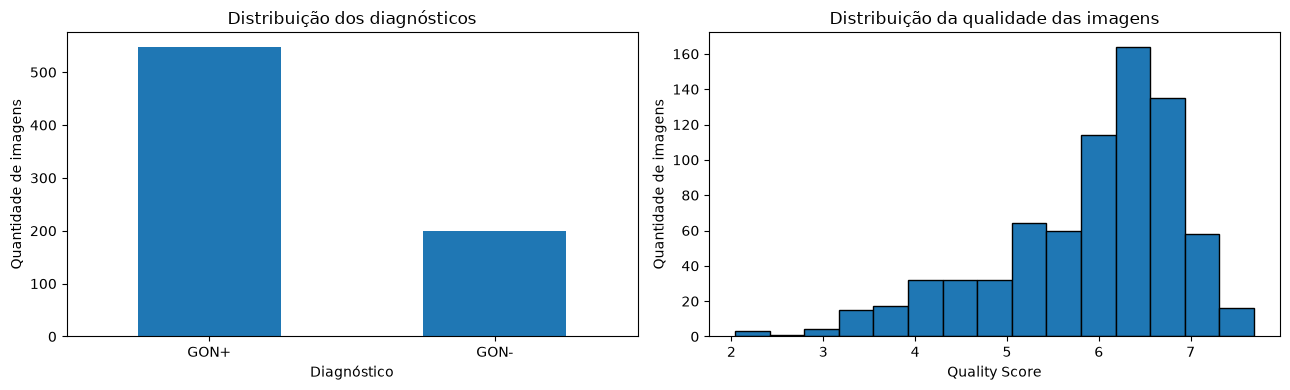

In [10]:
# 4. Visualização das distribuições
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

distribuicao_labels.plot(
    kind="bar",
    ax=axes[0],
    title="Distribuição dos diagnósticos"
)

axes[0].set_xlabel("Diagnóstico")
axes[0].set_ylabel("Quantidade de imagens")
axes[0].tick_params(axis="x", rotation=0)

axes[1].hist(
    df_audit["Quality Score"],
    bins=15,
    edgecolor="black"
)

axes[1].set_title("Distribuição da qualidade das imagens")
axes[1].set_xlabel("Quality Score")
axes[1].set_ylabel("Quantidade de imagens")

plt.tight_layout()
plt.show()

## Auditoria de integridade

Vamos conferir se o CSV e a pasta de imagens batem (nomes de arquivo, nomes duplicados, IDs de pacientes) e se há **arquivos com conteúdo idêntico**.

In [11]:
# Localizar imagens
arquivos_imagem = [
    p for p in IMAGES_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in EXTENSOES_IMAGEM
]

nomes_imagens = [p.name for p in arquivos_imagem]
nomes_csv = df_audit["Image Name"].astype(str).str.strip().tolist()

contador_arquivos = Counter(nomes_imagens)
contador_csv = Counter(nomes_csv)

# Verificar inconsistências
imagens_ausentes = set(nomes_csv) - set(nomes_imagens)
imagens_nao_catalogadas = set(nomes_imagens) - set(nomes_csv)

nomes_duplicados_disco = [
    nome for nome, quantidade in contador_arquivos.items()
    if quantidade > 1
]

nomes_duplicados_csv = [
    nome for nome, quantidade in contador_csv.items()
    if quantidade > 1
]

# Verificar IDs de pacientes
ids_pacientes = set(df_audit["Patient"].unique())

intervalo_ids = set(
    range(
        df_audit["Patient"].min(),
        df_audit["Patient"].max() + 1
    )
)

ids_ausentes = sorted(intervalo_ids - ids_pacientes)

# Resultados
print("=== INTEGRIDADE DAS IMAGENS ===")
print(f"Imagens encontradas na pasta: {len(arquivos_imagem)}")
print(f"Registros no CSV: {len(df_audit)}")
print(f"Nomes únicos no CSV: {len(set(nomes_csv))}")
print(f"Imagens referenciadas inexistentes: {len(imagens_ausentes)}")
print(f"Imagens não catalogadas: {len(imagens_nao_catalogadas)}")
print(f"Nomes duplicados na pasta: {len(nomes_duplicados_disco)}")
print(f"Nomes duplicados no CSV: {len(nomes_duplicados_csv)}")

print("\n=== IDENTIFICADORES DOS PACIENTES ===")
print(f"Pacientes únicos: {len(ids_pacientes)}")
print(f"IDs ausentes no intervalo: {ids_ausentes}")

# Exemplos de inconsistências, caso existam
if imagens_ausentes:
    print("\nImagens ausentes (amostra):", list(imagens_ausentes)[:10])

if imagens_nao_catalogadas:
    print("\nImagens não catalogadas (amostra):", list(imagens_nao_catalogadas)[:10])

if nomes_duplicados_disco:
    print("\nNomes duplicados na pasta:", nomes_duplicados_disco[:10])

if nomes_duplicados_csv:
    print("\nNomes duplicados no CSV:", nomes_duplicados_csv[:10])

=== INTEGRIDADE DAS IMAGENS ===
Imagens encontradas na pasta: 747
Registros no CSV: 747
Nomes únicos no CSV: 747
Imagens referenciadas inexistentes: 0
Imagens não catalogadas: 0
Nomes duplicados na pasta: 0
Nomes duplicados no CSV: 0

=== IDENTIFICADORES DOS PACIENTES ===
Pacientes únicos: 288
IDs ausentes no intervalo: [182]


**Paciente 182 ausente.** Os IDs vão de 0 a 288 (289 posições), mas há 288 pacientes. Só o 182 não aparece. Isso não é erro: o dataset simplesmente não tem esse paciente. Não vamos renumerar os IDs, para manter os originais.

Obs.: o README do dataset diz que os IDs começam em 1, mas existe o paciente 0. É só uma imprecisão da documentação.

### Arquivos idênticos

Nomes diferentes não garantem imagens diferentes. Calculamos o hash SHA-256 de cada arquivo, uma "impressão digital" do conteúdo: arquivos iguais byte a byte têm o mesmo hash. Com ele:
1. Conferimos os arquivos com o `SHA256SUMS.txt` que vem com o dataset (o download está íntegro?).
2. Procuramos arquivos idênticos com nomes diferentes.

In [12]:
hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(arquivos_imagem)}

# 1. Conferência com o SHA256SUMS.txt do dataset (linhas no formato "hash Images/nome.jpg")
esperados = {}
for linha in (DATA_DIR / "SHA256SUMS.txt").read_text().splitlines():
    valor, nome = linha.split(maxsplit=1)
    esperados[nome.lstrip("*")] = valor
divergentes = [n for n, h in hashes.items() if esperados.get(f"Images/{n}") != h]
print("=== CONFERÊNCIA COM SHA256SUMS.txt ===")
print(f"Imagens conferidas: {len(hashes)} | divergentes: {len(divergentes)}")

# 2. Arquivos idênticos
df_hash = df_audit.assign(hash=df_audit["Image Name"].map(hashes))
repetidos = df_hash[df_hash.duplicated("hash", keep=False)]
grupos_identicos = (
    repetidos.groupby("hash", sort=False)
    .agg(
        imagens=("Image Name", " = ".join),
        pacientes=("Patient", lambda s: sorted(set(s))),
        diagnostico=("Label", lambda s: "/".join(sorted(set(s)))),
        qualidade=("Quality Score", lambda s: " = ".join(f"{v:.2f}" for v in s)),
    )
    .reset_index(drop=True)
)
grupos_identicos["entre pacientes diferentes"] = grupos_identicos["pacientes"].map(len) > 1

print("\n=== ARQUIVOS IDÊNTICOS ===")
print(f"Grupos de arquivos idênticos: {len(grupos_identicos)} "
      f"({int(grupos_identicos['entre pacientes diferentes'].sum())} envolvem pacientes diferentes)")
print(f"Imagens que são cópia de outra: {int(df_hash.duplicated('hash').sum())}")
display(grupos_identicos)

=== CONFERÊNCIA COM SHA256SUMS.txt ===
Imagens conferidas: 747 | divergentes: 0

=== ARQUIVOS IDÊNTICOS ===
Grupos de arquivos idênticos: 10 (6 envolvem pacientes diferentes)
Imagens que são cópia de outra: 10


,imagens,pacientes,diagnostico,qualidade,entre pacientes diferentes
0,56_0.jpg = 56_1.jpg,[56],GON+,6.21 = 6.21,False
1,65_5.jpg = 110_0.jpg,"[65, 110]",GON+,6.67 = 6.67,True
2,81_0.jpg = 110_2.jpg,"[81, 110]",GON+,5.35 = 5.35,True
3,81_1.jpg = 110_1.jpg,"[81, 110]",GON+,6.74 = 6.74,True
4,81_2.jpg = 180_2.jpg,"[81, 180]",GON+,7.36 = 7.36,True
5,86_0.jpg = 86_1.jpg,[86],GON+,6.92 = 6.92,False
6,94_0.jpg = 94_1.jpg,[94],GON+,5.17 = 5.17,False
7,148_0.jpg = 148_1.jpg,[148],GON+,5.88 = 5.88,False
8,187_0.jpg = 197_0.jpg,"[187, 197]",GON-,7.26 = 7.26,True
9,239_0.jpg = 257_0.jpg,"[239, 257]",GON-,6.36 = 6.36,True


**O download está íntegro** (nenhum arquivo diverge do `SHA256SUMS.txt`), mas **o dataset tem 10 pares de arquivos idênticos**. A nota de qualidade também é igual em cada par, o que confirma que são cópias, e não fotos diferentes que por acaso coincidem.

- **4 pares dentro do mesmo paciente** (56, 86, 94 e 148): a mesma foto aparece duas vezes.
- **6 pares entre pacientes diferentes:** os pacientes 65, 81, 110 e 180 compartilham fotos (provavelmente são a mesma pessoa ou houve erro de catalogação), assim como 187 e 197, e 239 e 257. Nenhum par mistura diagnósticos.

**Por que isso importa para a clusterização:**
- Duas cópias sempre caem no mesmo cluster. Isso infla um pouco a estabilidade e a coesão por paciente.
- Testes e divisões "por paciente" assumem que cada ID é uma pessoa diferente. Com fotos compartilhadas entre IDs, a mesma imagem pode ir para o treino com um ID e para o teste com outro.

**Decisão:** manter **uma cópia** de cada arquivo (747 → 737 imagens) e formar **grupos de pacientes**: IDs ligados por um arquivo idêntico passam a ser tratados como uma só pessoa (288 → 283 grupos). A tabela é salva em `outputs/auditoria_duplicatas.csv` para ser usada na clusterização.

Esta auditoria só encontra cópias exatas. Fotos quase idênticas (a mesma foto recomprimida, por exemplo) não aparecem aqui.

In [13]:
# Grupos de pacientes: IDs ligados por um arquivo idêntico viram um único grupo (união de conjuntos)
grupo_de = {p: p for p in df_audit["Patient"].unique()}


def raiz(p):
    while grupo_de[p] != p:
        p = grupo_de[p]
    return p


for pacientes in grupos_identicos["pacientes"]:
    for p in pacientes[1:]:
        a, b = raiz(pacientes[0]), raiz(p)
        if a != b:
            grupo_de[max(a, b)] = min(a, b)    # o grupo recebe o menor ID

auditoria = df_hash[["Image Name", "Patient", "Label", "Quality Score", "hash"]].assign(
    grupo_paciente=lambda d: d["Patient"].map(raiz),
    copia_de_outra=df_hash.duplicated("hash"),   # True = já existe um arquivo idêntico antes no CSV
)
auditoria.to_csv(OUT_DIR / "auditoria_duplicatas.csv", index=False)

print(f"Imagens mantidas (uma cópia de cada): {int((~auditoria['copia_de_outra']).sum())} de {len(auditoria)}")
print(f"Grupos de pacientes: {auditoria['grupo_paciente'].nunique()} (IDs originais: {auditoria['Patient'].nunique()})")
print("Grupos com mais de um ID:")
for g, ids in auditoria.groupby("grupo_paciente")["Patient"].unique().items():
    if len(ids) > 1:
        print(f"   grupo {g}: pacientes {sorted(int(i) for i in ids)}")

Imagens mantidas (uma cópia de cada): 737 de 747
Grupos de pacientes: 283 (IDs originais: 288)
Grupos com mais de um ID:
   grupo 65: pacientes [65, 81, 110, 180]
   grupo 187: pacientes [187, 197]
   grupo 239: pacientes [239, 257]


## Auditoria técnica das imagens

Vamos checar as 747 imagens: resolução, modo de cor, formato real do arquivo e se todas abrem sem erro.

In [14]:
registros_imagens = []
erros_leitura = []

for caminho in arquivos_imagem:
    try:
        with Image.open(caminho) as imagem:
            registro = {
                "Image Name": caminho.name,
                "Extension": caminho.suffix.lower(),
                "Width": imagem.width,
                "Height": imagem.height,
                "Mode": imagem.mode,
                "Format": imagem.format,
            }

            # Garante que a imagem pode ser decodificada de verdade
            imagem.load()

            registros_imagens.append(registro)

    except Exception as erro:
        erros_leitura.append({
            "arquivo": caminho.name,
            "erro": str(erro)
        })

# DataFrame com as propriedades técnicas
df_imagens = pd.DataFrame(registros_imagens)

In [15]:
print("=== INTEGRIDADE DOS ARQUIVOS ===")
print(f"Imagens analisadas: {len(df_imagens)}")
print(f"Falhas de leitura: {len(erros_leitura)}")

=== INTEGRIDADE DOS ARQUIVOS ===
Imagens analisadas: 747
Falhas de leitura: 0


In [16]:
print("=== PROPORÇÃO DAS IMAGENS ===")
print(f"Todas quadradas (largura = altura): {(df_imagens['Width'] == df_imagens['Height']).all()}")

print("\n=== DISTRIBUIÇÃO DAS RESOLUÇÕES ===")
display(
    df_imagens.groupby(["Width", "Height"])
    .size()
    .to_frame("Quantidade")
    .sort_values("Quantidade", ascending=False)
)

=== PROPORÇÃO DAS IMAGENS ===
Todas quadradas (largura = altura): True

=== DISTRIBUIÇÃO DAS RESOLUÇÕES ===


,,Quantidade
Width,Height,
1894,1894,53
1893,1893,39
1881,1881,29
1878,1878,29
1896,1896,28
...,...,...
1937,1937,1
1943,1943,1
1938,1938,1


Todas as imagens são quadradas (largura = altura), então redimensionar para 224 × 224 não distorce a proporção. A resolução varia pouco: o lado vai de 1873 a 1960 pixels. Isso não exige tratamento especial.

In [17]:
print("\n=== MODOS DE CORES ===")
display(
    df_imagens["Mode"]
    .value_counts()
    .to_frame("Quantidade")
)


=== MODOS DE CORES ===


,Quantidade
Mode,
RGB,747


Todas as imagens estão em RGB, então não há imagens em tons de cinza para tratar.

In [18]:
print("\n=== FORMATOS ===")
display(
    df_imagens["Format"]
    .value_counts()
    .to_frame("Quantidade")
)


=== FORMATOS ===


,Quantidade
Format,
JPEG,736
PNG,11


In [19]:
df_formato = df_audit.merge(df_imagens, on="Image Name", validate="one_to_one")

print("=== FORMATO REAL x EXTENSÃO DO ARQUIVO ===")
display(pd.crosstab(df_formato["Format"], df_formato["Extension"]))

print("\n=== FORMATO REAL x DIAGNÓSTICO ===")
display(pd.crosstab(df_formato["Format"], df_formato["Label"]))

imagens_png = df_formato[df_formato["Format"] == "PNG"]
qualidade_jpeg = df_formato.loc[df_formato["Format"] == "JPEG", "Quality Score"].mean()

print(f"\nPacientes com imagens PNG: {sorted(int(p) for p in imagens_png['Patient'].unique())}")
print(f"Qualidade média: PNG = {imagens_png['Quality Score'].mean():.2f} | JPEG = {qualidade_jpeg:.2f}")

=== FORMATO REAL x EXTENSÃO DO ARQUIVO ===


Extension,.jpg
Format,
JPEG,736
PNG,11



=== FORMATO REAL x DIAGNÓSTICO ===


Label,GON+,GON-
Format,,
JPEG,548,188
PNG,0,11



Pacientes com imagens PNG: [240, 247, 254, 278, 285, 287, 288]
Qualidade média: PNG = 5.38 | JPEG = 5.91


Temos 736 arquivos JPEG e 11 PNG, mas **todos** têm extensão `.jpg`. Ou seja, 11 arquivos são PNG com nome `.jpg`. O Pillow e o Torchvision abrem esses arquivos normalmente (eles detectam o formato pelo conteúdo), então não precisamos converter.

Porém, os 11 PNG são **todos `GON-`** e vêm de 7 pacientes com IDs altos (240 a 288). A qualidade média deles também é menor (5,38 contra 5,91 dos JPEG), na direção contrária da média dos `GON-` (6,07). Isso sugere que essas imagens têm origem ou processamento diferente. Elas podem formar um cluster próprio sem nenhuma relação com glaucoma.

=== ESTATÍSTICAS DAS DIMENSÕES ===


,Width,Height
count,747.00,747.00
mean,1899.09,1899.09
std,18.42,18.42
min,1873.00,1873.00
25%,1886.00,1886.00
50%,1894.00,1894.00
75%,1909.50,1909.50
max,1960.00,1960.00



=== LARGURA (px) POR DIAGNÓSTICO ===


,count,mean,std,min,50%,max
Label,,,,,,
GON+,548.0,1902.8,19.7,1873.0,1897.5,1960.0
GON-,199.0,1888.9,7.9,1876.0,1892.0,1910.0


Teste de Levene (dispersão da largura, por paciente): p = 5e-12
Imagens com mais de 1910 px: 181 (181 GON+)


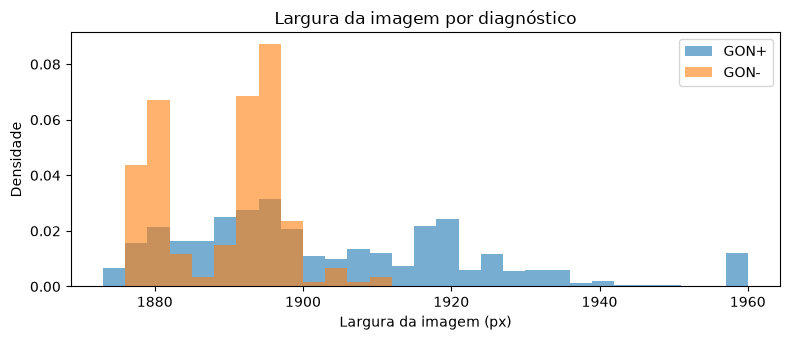

In [20]:
print("=== ESTATÍSTICAS DAS DIMENSÕES ===")
display(df_imagens[["Width", "Height"]].describe().round(2))

print("\n=== LARGURA (px) POR DIAGNÓSTICO ===")
display(df_formato.groupby("Label")["Width"].describe()[["count", "mean", "std", "min", "50%", "max"]].round(1))

# A dispersão da largura é diferente entre os diagnósticos? (Levene com mediana, uma média por paciente)
largura_pac = df_formato.groupby(["Patient", "Label"])["Width"].mean().reset_index()
levene = stats.levene(
    largura_pac.loc[largura_pac["Label"] == "GON+", "Width"],
    largura_pac.loc[largura_pac["Label"] == "GON-", "Width"],
    center="median",
)
print(f"Teste de Levene (dispersão da largura, por paciente): p = {levene.pvalue:.2g}")
print(f"Imagens com mais de 1910 px: {(df_formato['Width'] > 1910).sum()} "
      f"({(df_formato.loc[df_formato['Width'] > 1910, 'Label'] == 'GON+').sum()} GON+)")

fig, ax = plt.subplots(figsize=(8, 3.5))
faixa = np.arange(df_formato["Width"].min(), df_formato["Width"].max() + 3, 3)
for rotulo in ["GON+", "GON-"]:
    ax.hist(df_formato.loc[df_formato["Label"] == rotulo, "Width"], bins=faixa, alpha=0.6, label=rotulo, density=True)
ax.set_xlabel("Largura da imagem (px)")
ax.set_ylabel("Densidade")
ax.set_title("Largura da imagem por diagnóstico")
ax.legend()
plt.tight_layout()
plt.show()

Todas as imagens são quadradas e o lado vai de 1873 a 1960 px, o que não exige tratamento especial.

**Mas a largura se distribui de forma diferente entre os diagnósticos.** As `GON-` ficam num intervalo estreito (desvio de 7,9 px, máximo de 1910 px). As `GON+` variam bem mais (desvio de 19,7 px, até 1960 px). As 181 imagens com mais de 1910 px são todas `GON+`. A diferença de dispersão é clara mesmo comparando por paciente (teste de Levene, p ≈ 5 × 10⁻¹²).

A largura não é uma característica clínica: ela depende do equipamento, do recorte e do processamento. Junto com o ID e o formato PNG, é mais um indício de que `GON+` e `GON-` podem ter vindo de lotes diferentes. Por isso a largura também fica fora do K-Means e serve só para interpretar.

In [21]:
if erros_leitura:
    print("\n=== ERROS ENCONTRADOS ===")
    display(pd.DataFrame(erros_leitura))

## Brilho e nitidez

A inspeção visual (mais abaixo) mostra iluminação e foco bem variados. Antes de agrupar, vale medir isso, porque o K-Means tende a separar as imagens pelo que mais varia.

Para cada imagem (reduzida para 256 × 256 só para esta medida), calculamos dentro do campo de visão (a região com retina, sem a borda preta):
- **Brilho:** média do canal vermelho, o mais intenso no fundo de olho.
- **Nitidez:** gradiente médio (filtro de Sobel) da imagem em cinza, longe da borda do campo de visão.

As comparações entre diagnósticos são feitas por paciente.

=== BRILHO E NITIDEZ POR DIAGNÓSTICO (por imagem) ===


Label             GON+     GON-
brilho  count  548.000  199.000
        mean     0.427    0.448
        std      0.105    0.110
        min      0.136    0.234
        25%      0.356    0.367
        50%      0.420    0.444
        75%      0.498    0.517
        max      0.806    0.829
nitidez count  548.000  199.000
        mean     0.043    0.040
        std      0.018    0.010
        min      0.014    0.021
        25%      0.031    0.033
        50%      0.039    0.038
        75%      0.050    0.045
        max      0.124    0.086

=== COMPARAÇÃO POR PACIENTE ===


,mediana GON+,mediana GON-,P(GON- > GON+),p,pacientes
brilho,0.418,0.440,0.555,0.126,288.0
nitidez,0.040,0.038,0.454,0.196,288.0


=== CORRELAÇÃO DE SPEARMAN ===
   brilho x Quality Score: rho = 0.35
   nitidez x Quality Score: rho = 0.31
   brilho x nitidez: rho = 0.66


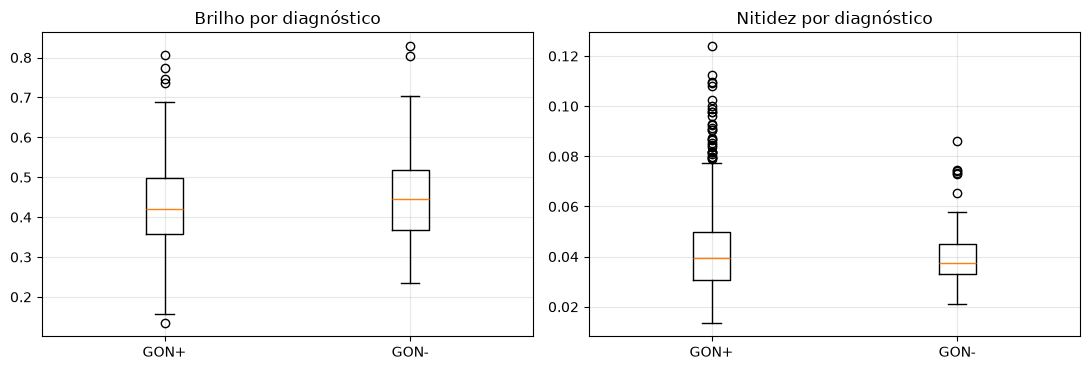

In [22]:
LUMINANCIA = np.array([0.299, 0.587, 0.114], dtype=np.float32)


def brilho_e_nitidez(caminho, lado=256):
    with Image.open(caminho) as imagem:
        rgb = np.asarray(imagem.convert("RGB").resize((lado, lado), Image.Resampling.BILINEAR), dtype=np.float32) / 255
    campo = ndi.binary_fill_holes(ndi.binary_opening(rgb.max(axis=2) > 15 / 255, iterations=2))
    interior = ndi.binary_erosion(campo, iterations=4)          # evita a transição retina/borda preta
    cinza = rgb @ LUMINANCIA
    gradiente = np.hypot(ndi.sobel(cinza, axis=1), ndi.sobel(cinza, axis=0))
    return {"Image Name": caminho.name,
            "brilho": float(rgb[..., 0][campo].mean()),
            "nitidez": float(gradiente[interior].mean())}


df_brilho = df_audit.merge(
    pd.DataFrame([brilho_e_nitidez(IMAGES_DIR / n) for n in df_audit["Image Name"]]),
    on="Image Name", validate="one_to_one",
)

print("=== BRILHO E NITIDEZ POR DIAGNÓSTICO (por imagem) ===")
display(df_brilho.groupby("Label")[["brilho", "nitidez"]].describe().T.round(3))

print("=== COMPARAÇÃO POR PACIENTE ===")
display(pd.DataFrame({c: comparar_por_paciente(df_brilho, c) for c in ["brilho", "nitidez"]}).T.round(3))

print("=== CORRELAÇÃO DE SPEARMAN ===")
for a, b in [("brilho", "Quality Score"), ("nitidez", "Quality Score"), ("brilho", "nitidez")]:
    print(f"   {a} x {b}: rho = {stats.spearmanr(df_brilho[a], df_brilho[b]).statistic:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, coluna in zip(axes, ["brilho", "nitidez"]):
    ax.boxplot([df_brilho.loc[df_brilho["Label"] == r, coluna] for r in ["GON+", "GON-"]], tick_labels=["GON+", "GON-"])
    ax.set_title(f"{coluna.capitalize()} por diagnóstico")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

- **O brilho varia muito entre as imagens** (canal vermelho de cerca de 0,14 a 0,83), bem mais do que entre os diagnósticos. As medianas por paciente são parecidas e a diferença não é significativa (p ≈ 0,13).
- **A nitidez também não difere entre os diagnósticos** (p ≈ 0,20), mas as `GON+` são mais heterogêneas: têm tanto as imagens mais borradas quanto as mais nítidas.
- **Brilho e nitidez andam juntos** (ρ ≈ 0,66), e os dois acompanham o `Quality Score` (ρ ≈ 0,35 e 0,31).

**O que esperar na clusterização:** como brilho e nitidez são grandes fontes de variação e não acompanham o diagnóstico, características que medem cor e textura (as tradicionais, por exemplo) tendem a gerar clusters de **condição de captura**, não de doença.

## Inspeção visual de uma amostra

Vamos olhar algumas imagens para checar:
- Se o disco óptico está centralizado.
- Se a iluminação varia muito.
- Se há imagens desfocadas ou com artefatos.
- Se há diferença visível entre `GON+` e `GON-`.
- Se o `Quality Score` combina com o que vemos.

Escolhemos 1 imagem por paciente (para nenhum paciente aparecer repetido) e 2 imagens por faixa de qualidade (baixa, média e alta) em cada diagnóstico.

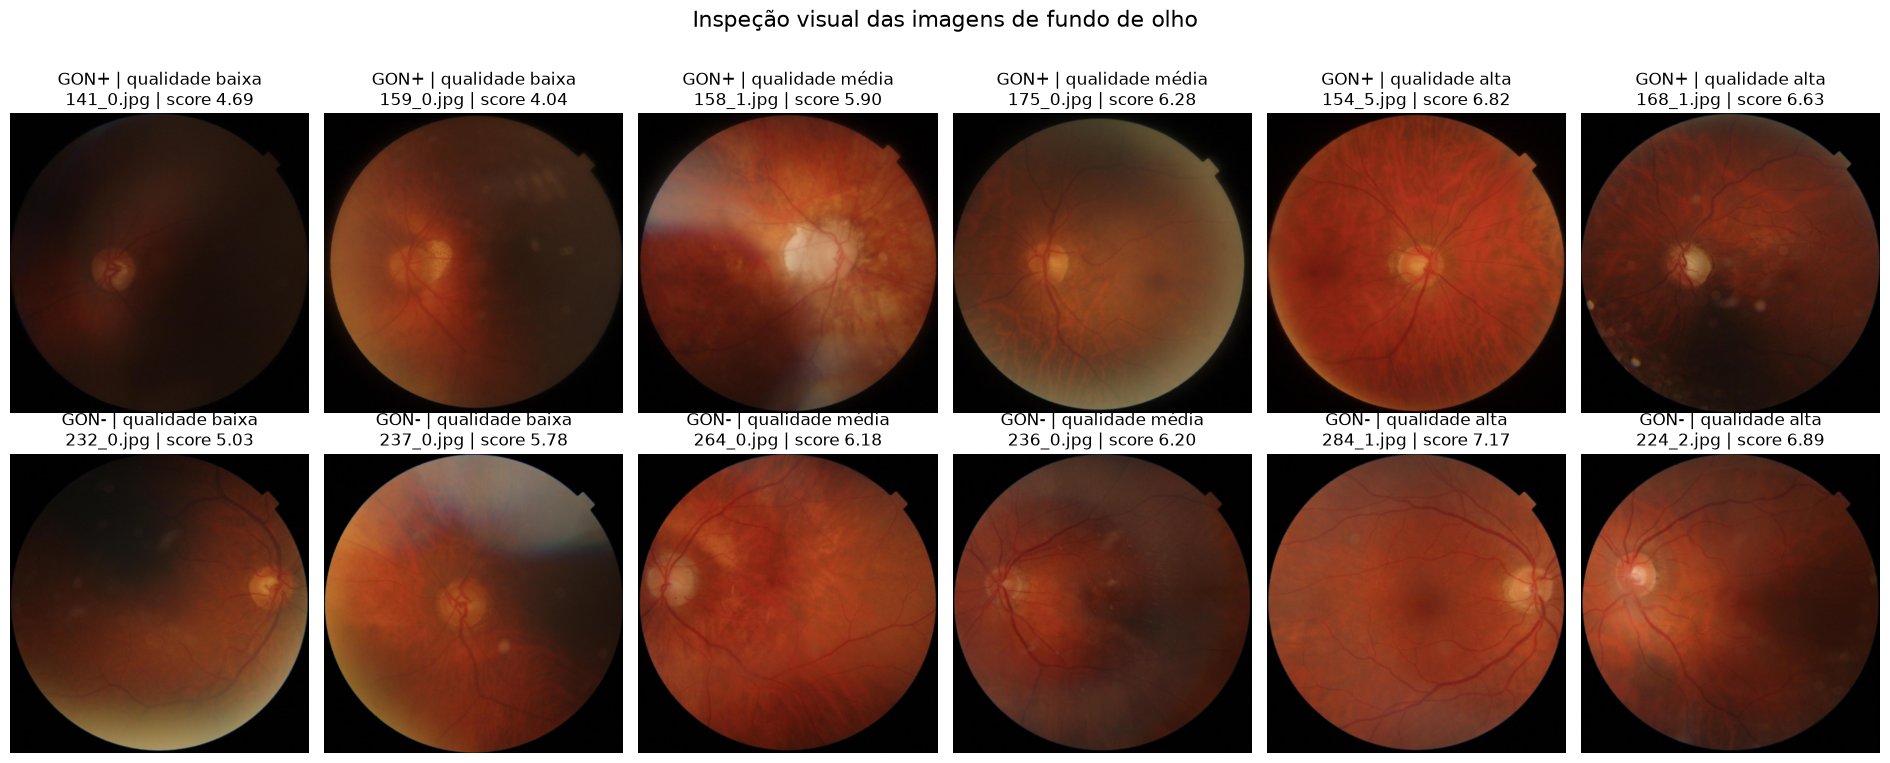

Total de imagens visualizadas: 12


In [23]:
# Junta os metadados com as propriedades técnicas das imagens
df_visualizacao = df_audit.merge(
    df_imagens,
    on="Image Name",
    how="inner",
    validate="one_to_one"
)

# Uma imagem por paciente
amostra_pacientes = (
    df_visualizacao
    .groupby("Patient", group_keys=False)
    .sample(n=1, random_state=42)
)

# Divide cada diagnóstico em 3 faixas de qualidade e sorteia 2 imagens por faixa
faixas = ["Baixa", "Média", "Alta"]
amostras = []

for diagnostico in ["GON+", "GON-"]:
    grupo = amostra_pacientes[amostra_pacientes["Label"] == diagnostico].copy()
    grupo["Faixa"] = pd.qcut(grupo["Quality Score"], q=3, labels=faixas)

    for faixa in faixas:
        selecao = grupo[grupo["Faixa"] == faixa]
        amostras.append(selecao.sample(n=min(2, len(selecao)), random_state=42))

df_amostra = pd.concat(amostras).reset_index(drop=True)

# Visualização (diagnóstico e faixa ficam no título, porque axis("off") esconde os rótulos dos eixos)
fig, axes = plt.subplots(2, 6, figsize=(19, 8))

for linha, diagnostico in enumerate(["GON+", "GON-"]):
    for coluna, faixa in enumerate(faixas):
        grupo = df_amostra[
            (df_amostra["Label"] == diagnostico) &
            (df_amostra["Faixa"] == faixa)
        ]

        for repeticao in range(2):
            ax = axes[linha, coluna * 2 + repeticao]

            if repeticao < len(grupo):
                registro = grupo.iloc[repeticao]

                with Image.open(IMAGES_DIR / registro["Image Name"]) as imagem:
                    ax.imshow(imagem.convert("RGB"))

                ax.set_title(
                    f"{diagnostico} | qualidade {faixa.lower()}\n"
                    f"{registro['Image Name']} | score {registro['Quality Score']:.2f}"
                )

            ax.axis("off")

fig.suptitle("Inspeção visual das imagens de fundo de olho", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print(f"Total de imagens visualizadas: {len(df_amostra)}")

**O que vemos nas imagens:**

- **Iluminação irregular:** algumas imagens têm áreas bem escuras (141_0, 159_0, 232_0). Outras são mais claras ou têm brilho desigual (154_5, 158_1, 224_2).
- **Detalhes:** a nitidez dos vasos sanguíneos e do disco óptico varia bastante entre as imagens.
- **Bordas pretas:** todas as imagens têm uma área preta ao redor da retina. A rede neural também vai processar esses pixels.
- **Posição do disco óptico:** ele aparece à esquerda em algumas imagens e à direita em outras (provavelmente por serem olhos esquerdos e direitos). Por isso, um recorte central pode cortar o disco.

**Hipótese inicial:** começar com um pré-processamento simples.

- Manter o campo de visão completo (sem recortar).
- Redimensionar para 224 × 224.
- Converter para tensor.
- Normalizar com os valores esperados pelos pesos pré-treinados da MobileNetV3.

Por enquanto, não vamos aplicar CLAHE, remover as bordas pretas nem recortar as imagens.

## Imagens de menor e maior qualidade

As 3 piores e as 3 melhores imagens de cada diagnóstico, considerando todas as imagens (não só uma por paciente).

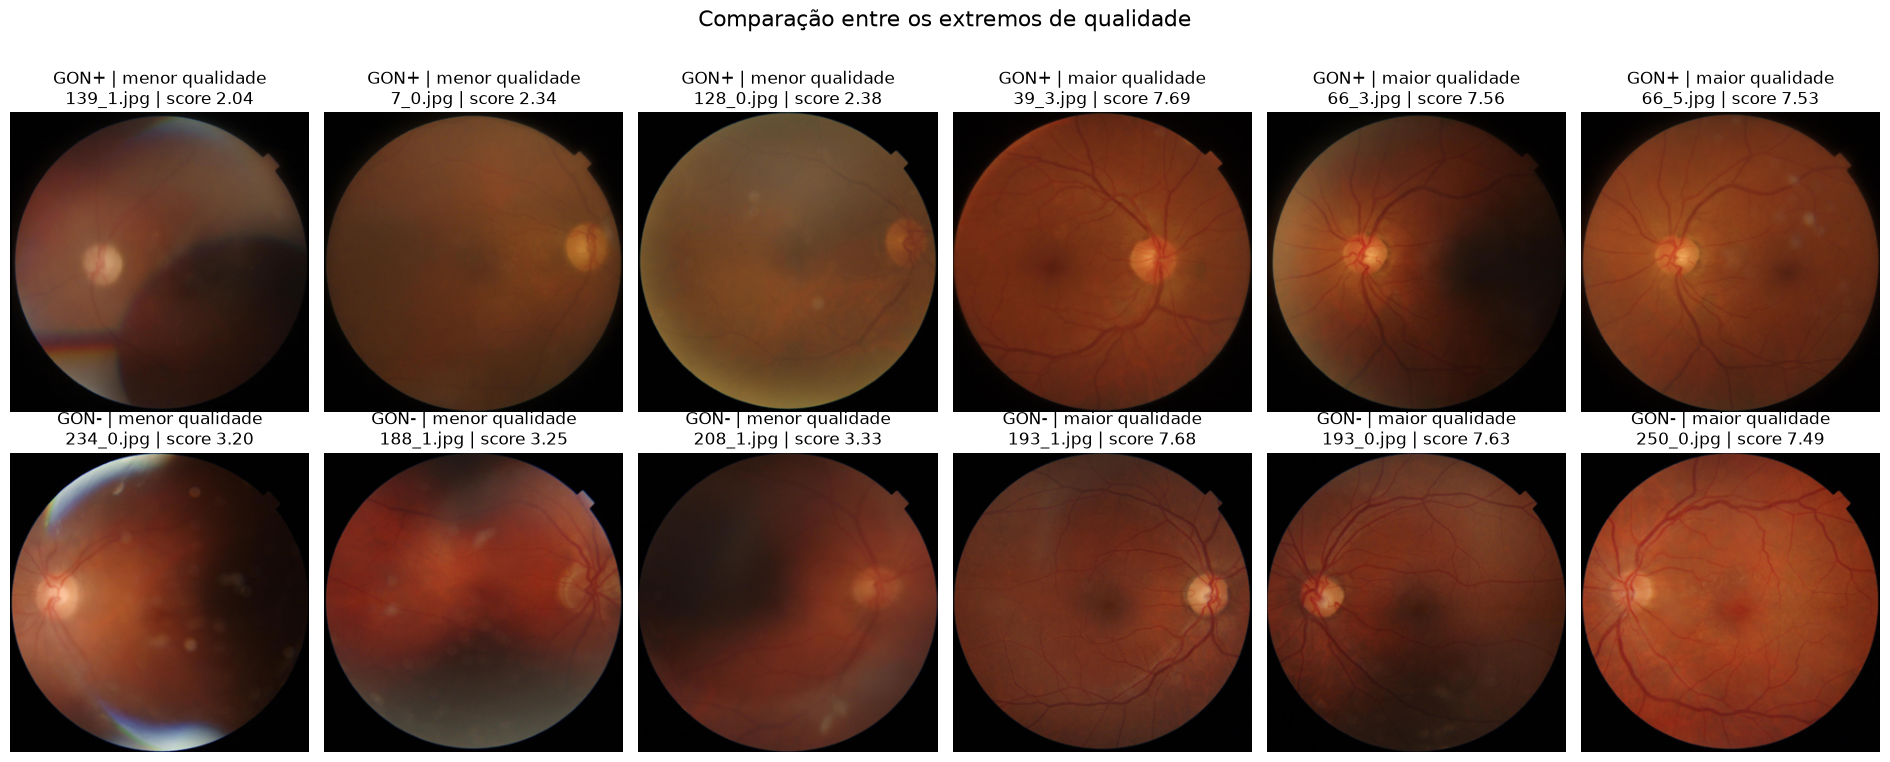

In [24]:
fig, axes = plt.subplots(2, 6, figsize=(19, 8))

for linha, diagnostico in enumerate(["GON+", "GON-"]):
    grupo = df_visualizacao[df_visualizacao["Label"] == diagnostico]

    menores = grupo.nsmallest(3, "Quality Score")
    maiores = grupo.nlargest(3, "Quality Score")
    selecao = pd.concat([menores, maiores])

    for coluna, (_, registro) in enumerate(selecao.iterrows()):
        with Image.open(IMAGES_DIR / registro["Image Name"]) as imagem:
            imagem = imagem.convert("RGB")
            imagem.thumbnail((320, 320))
            axes[linha, coluna].imshow(imagem)

        extremo = "menor qualidade" if coluna < 3 else "maior qualidade"

        axes[linha, coluna].set_title(
            f"{diagnostico} | {extremo}\n"
            f"{registro['Image Name']} | score {registro['Quality Score']:.2f}"
        )
        axes[linha, coluna].axis("off")

fig.suptitle("Comparação entre os extremos de qualidade", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**Menor qualidade:**
- Sombras e áreas escuras.
- Reflexos e artefatos de captura.
- Vasos sanguíneos pouco nítidos.

**Maior qualidade:**
- Vasos e disco óptico bem definidos.
- Iluminação mais uniforme, mas ainda com algumas áreas escuras (como em 66_3 e 193_0).
- Imagem mais nítida.

O `Quality Score` parece coerente com o que vemos nas imagens.

**Decisões de pré-processamento**

| Operação | Decisão | Motivo |
|---|---|---|
| Remover imagens de baixa qualidade | Não | Manter a distribuição original. A qualidade é usada depois, para interpretar e numa análise de sensibilidade. |
| Remover cópias idênticas | Sim | 10 arquivos são cópias exatas de outros. Mantemos uma cópia de cada (747 → 737). |
| Converter para tons de cinza | Não | A cor pode ter informação útil. |
| Aplicar CLAHE (realce de contraste) | Não, por enquanto | Nivelaria brilho e contraste, justamente os sinais de qualidade que queremos detectar nos clusters. Também pode amplificar ruído e tem parâmetros que não temos como escolher sem rótulos. |
| Recortar o disco óptico | Não | A posição dele varia entre as imagens (olhos esquerdos e direitos). |
| Remover bordas pretas da imagem | Não, por enquanto | As imagens são quadradas e a borda é parecida em todas. Nas estatísticas calculadas a partir dos pixels, a borda é excluída por uma máscara do campo de visão, sem alterar a imagem. |
| Redimensionar para 224 × 224 | Sim | A MobileNetV3 usa entrada de tamanho fixo. Como as imagens são quadradas, não há distorção. |
| Normalizar | Sim | Usar a normalização dos pesos pré-treinados (média e desvio do ImageNet). |

**Outras decisões:**
- `Quality Score`, ID do paciente, formato do arquivo e largura da imagem são usados **só para interpretar** os clusters, nunca como entrada do K-Means.
- Divisões e testes "por paciente" usam os **grupos de pacientes** da auditoria (IDs ligados por cópias idênticas formam um único grupo).
- Fazer análises de sensibilidade sem as imagens de pior qualidade e sem os 11 PNG.

## Teste de redimensionamento

Compara a imagem original com a versão redimensionada para 224 × 224, usando a pior e a melhor imagem de cada diagnóstico.

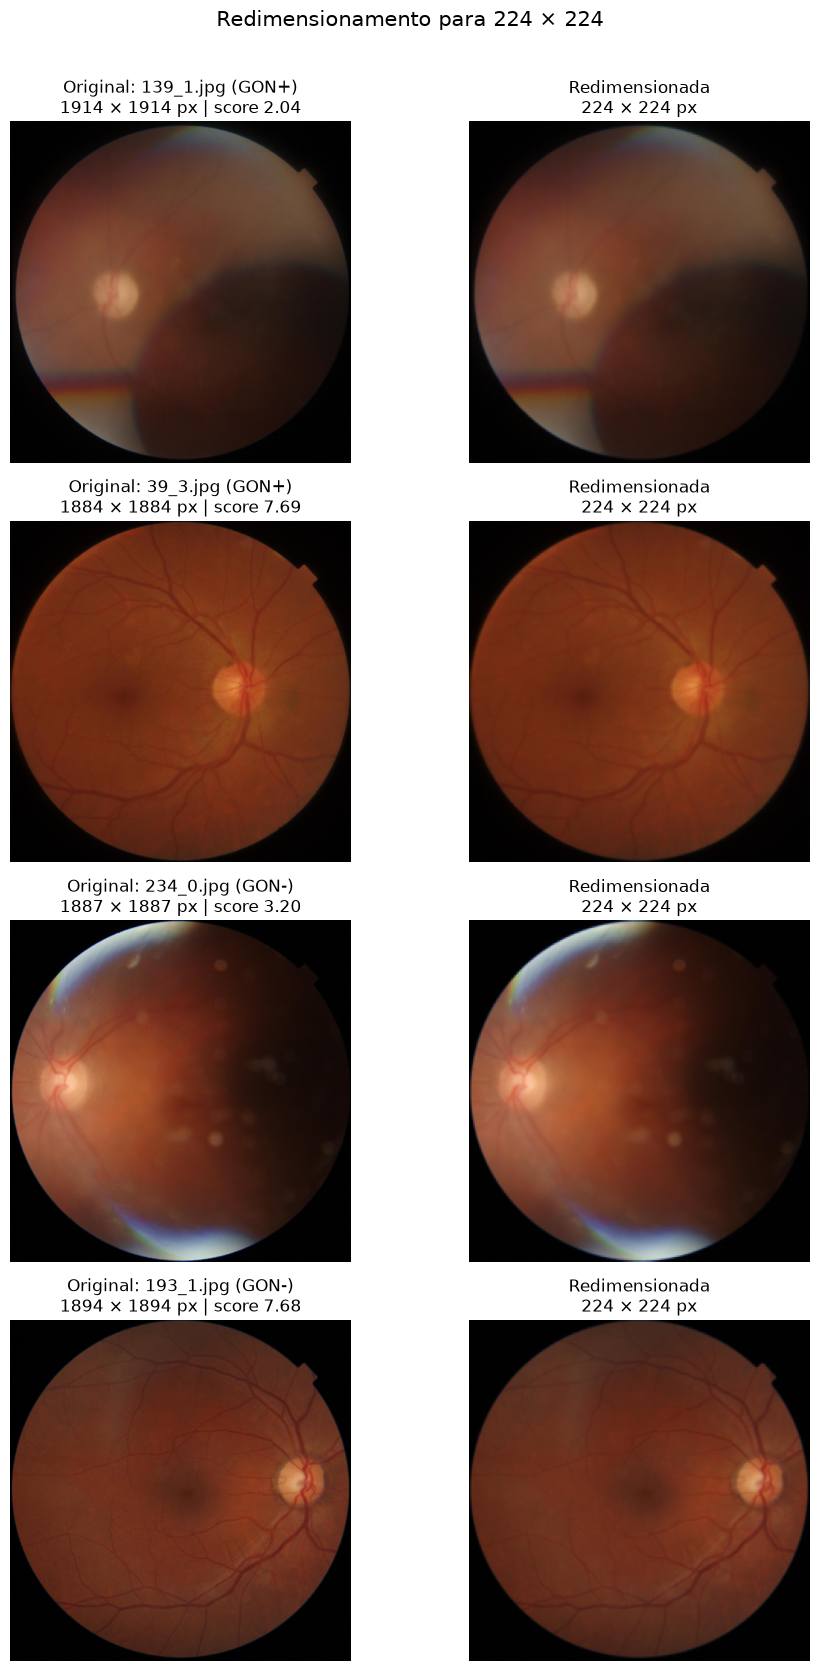

In [25]:
# Transformação geométrica inicial
redimensionar = transforms.Resize(
    size=(224, 224),
    interpolation=InterpolationMode.BILINEAR,
    antialias=True
)

# Pior e melhor imagem de cada diagnóstico
amostra = []

for diagnostico in ["GON+", "GON-"]:
    grupo = df_visualizacao[df_visualizacao["Label"] == diagnostico]

    amostra.extend([
        grupo.nsmallest(1, "Quality Score").iloc[0],
        grupo.nlargest(1, "Quality Score").iloc[0],
    ])

# Comparação visual
fig, axes = plt.subplots(4, 2, figsize=(10, 17))

for i, registro in enumerate(amostra):
    with Image.open(IMAGES_DIR / registro["Image Name"]) as imagem:
        imagem = imagem.convert("RGB")
        imagem_redimensionada = redimensionar(imagem)

        axes[i, 0].imshow(imagem)
        axes[i, 0].set_title(
            f"Original: {registro['Image Name']} ({registro['Label']})\n"
            f"{imagem.width} × {imagem.height} px | score {registro['Quality Score']:.2f}"
        )

        axes[i, 1].imshow(imagem_redimensionada)
        axes[i, 1].set_title(
            f"Redimensionada\n"
            f"{imagem_redimensionada.width} × {imagem_redimensionada.height} px"
        )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

fig.suptitle("Redimensionamento para 224 × 224", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

O redimensionamento mantém a aparência geral e o disco óptico continua visível. O que se perde são detalhes finos, como os vasos mais finos, já que o lado da imagem cai de cerca de 1900 para 224 pixels.

## Resumo para a clusterização

| Achado | Consequência |
|---|---|
| 747 imagens, 288 IDs de paciente, 73% `GON+` | Um cluster grande de `GON+` pode ser só a classe majoritária. |
| `GON+` têm mais imagens por paciente (2,95 contra 1,95) | Testes e reamostragens por paciente, não por imagem. |
| **ID do paciente = diagnóstico** (`GON+` de 0 a 186, `GON-` de 187 a 288) | O ID nunca entra como característica. Diferenças de lote ficam misturadas com o diagnóstico. |
| **10 arquivos são cópias exatas**, 6 deles entre IDs diferentes | Usar as 737 imagens únicas e os 283 grupos de pacientes nas divisões. |
| 11 PNG com extensão `.jpg`, todos `GON-` e de qualidade menor | Possível origem diferente. Verificar se formam cluster próprio. |
| Largura mais variada nas `GON+`; acima de 1910 px só há `GON+` | Mais um sinal de origem. Usar só para interpretar. |
| Qualidade um pouco menor nas `GON+` (efeito pequeno; p ≈ 0,01 por paciente) | `Quality Score` só para interpretar e para sensibilidade. |
| Brilho e nitidez variam muito, mas não com o diagnóstico | Esperar clusters de condição de captura. |
| Todas as imagens quadradas, RGB, legíveis e íntegras | Redimensionar para 224 × 224 sem distorção, sem CLAHE nem recorte. |